# Experiment 10 — Frozen Teacher Weak-Augmentation Agreement

**Objective:** Compare confidence-only pseudo-label selection against confidence plus class/location agreement across two weak views.

**Dataset:** Foggy Cityscapes, strong fog (beta = 0.02).

**Pilot:** 50 images, beginning with a one-image smoke test.

**Controls:** Frozen teacher, identical retained-box counts, ground truth used only after pseudo-label selection.


In [1]:
from pathlib import Path
import json, random, time
import cv2
import numpy as np
import torch

print('PyTorch:', torch.__version__)
print('Experiment 10 initialized')

PyTorch: 2.5.1
Experiment 10 initialized


In [2]:
import os, sys, json, time, hashlib, platform, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path.home() / 'Desktop/phd/vizuara/Deliverables/milestone2'
EXP = ROOT / 'Adaptive_teacher_Experiment 2'
REPO = EXP / 'research_code_results/adaptive_teacher_recovered/adaptive_teacher'
D2 = ROOT / 'detectron2'
CONFIG = EXP / 'research_code_results/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_v1/config.yaml'
CHECKPOINT = EXP / 'final_model_checkpoints/adaptive_teacher_080/model_final.pth'
OUT = EXP / 'local_final_teacher_evaluation'
OUT.mkdir(parents=True, exist_ok=True)
for p in [D2, REPO]:
    if str(p) not in sys.path: sys.path.insert(0, str(p))
for name,p in [('Detectron2',D2),('Adaptive Teacher source',REPO),('Config',CONFIG),('Checkpoint',CHECKPOINT)]:
    assert p.exists(), f'{name} missing: {p}'
print('Python:',sys.version.split()[0], '| Torch:',torch.__version__)
print('Platform:',platform.platform(), '| MPS available:',torch.backends.mps.is_available())
print('Output:',OUT)

Python: 3.10.10 | Torch: 2.5.1
Platform: macOS-26.6.2-arm64-arm-64bit | MPS available: True
Output: /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/local_final_teacher_evaluation


In [3]:

# Load the final Adaptive Teacher checkpoint on CPU.
assert CHECKPOINT.is_file(), f"Checkpoint missing: {CHECKPOINT}"

checkpoint = torch.load(
    str(CHECKPOINT),
    map_location="cpu",
    weights_only=False
)

assert "model" in checkpoint, "Checkpoint does not contain model weights"
teacher_keys = [
    key for key in checkpoint["model"]
    if key.startswith("modelTeacher.")
]

assert teacher_keys, "No teacher weights found in checkpoint"

print("Checkpoint loaded successfully")
print("Teacher parameter tensors:", len(teacher_keys))


Checkpoint loaded successfully
Teacher parameter tensors: 113


In [4]:
from detectron2.config import get_cfg
from detectron2.modeling import build_model
from detectron2 import _C
from adapteacher import add_ateacher_config
from adapteacher.modeling.meta_arch import vgg, rcnn
from adapteacher.modeling.proposal_generator import rpn
from adapteacher.modeling.roi_heads import fast_rcnn, roi_heads

cfg=get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(CONFIG))
cfg.MODEL.DEVICE='cpu'
# Save detections above 0.05 so all target score thresholds can be evaluated later.
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST=0.05
cfg.freeze()
print('Architecture:',cfg.MODEL.META_ARCHITECTURE)
print('Backbone:',cfg.MODEL.BACKBONE.NAME)
print('Training pseudo-label threshold:',cfg.SEMISUPNET.BBOX_THRESHOLD)
print('Inference score floor:',cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST)
model=build_model(cfg)
teacher_state={k[len('modelTeacher.'):]:v for k,v in checkpoint['model'].items() if k.startswith('modelTeacher.')}
load_result=model.load_state_dict(teacher_state,strict=False)
print('Missing keys:',len(load_result.missing_keys),'Unexpected keys:',len(load_result.unexpected_keys))
assert not load_result.missing_keys and not load_result.unexpected_keys, 'Do not evaluate a partially loaded model.'
model.eval()
del checkpoint, teacher_state
print('FINAL TEACHER LOADED SUCCESSFULLY')

Architecture: DAobjTwoStagePseudoLabGeneralizedRCNN
Backbone: build_vgg_backbone
Training pseudo-label threshold: 0.8
Inference score floor: 0.05
Missing keys: 0 Unexpected keys: 0
FINAL TEACHER LOADED SUCCESSFULLY


In [5]:

import cv2, numpy as np, torch, json, time
from pathlib import Path
from detectron2.data.transforms import ResizeShortestEdge

DATA = ROOT / "data/raw/foggy_cityscapes/leftImg8bit_trainvaltest_foggy/leftImg8bit_foggy/val"
RESULTS = EXP / "experiment_10_weak_augmentation_agreement"
RESULTS.mkdir(parents=True, exist_ok=True)

images = sorted(DATA.rglob("*_foggy_beta_0.02.png"))
assert len(images) >= 50
print("Strong-fog images:", len(images))

def predict_view(image, flipped=False):
    h, w = image.shape[:2]
    view = cv2.flip(image, 1) if flipped else image.copy()

    aug = ResizeShortestEdge(cfg.INPUT.MIN_SIZE_TEST, cfg.INPUT.MAX_SIZE_TEST)
    resized = aug.get_transform(view).apply_image(view)

    tensor = torch.as_tensor(
        np.ascontiguousarray(resized.transpose(2, 0, 1)),
        dtype=torch.float32,
        device="cpu"
    )

    with torch.inference_mode():
        output = model([{"image": tensor, "height": h, "width": w}])[0]

    inst = output["instances"].to("cpu")
    boxes = inst.pred_boxes.tensor.numpy().copy()

    if flipped and len(boxes):
        x1 = boxes[:, 0].copy()
        x2 = boxes[:, 2].copy()
        boxes[:, 0] = w - x2
        boxes[:, 2] = w - x1

    return [
        {"box": box.tolist(), "score": float(score), "class": int(cls)}
        for box, score, cls in zip(boxes, inst.scores, inst.pred_classes)
    ]

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return intersection / max(area_a + area_b - intersection, 1e-9)

def compare_predictions(a, b, threshold=0.5):
    results = []
    for pred in a:
        matches = [
            iou(pred["box"], other["box"])
            for other in b if pred["class"] == other["class"]
        ]
        agreement = max(matches, default=0.0)
        results.append({
            **pred,
            "agreement_iou": agreement,
            "agrees": agreement >= threshold,
            "combined_score": pred["score"] * agreement
        })
    return results

# Start with one image to measure CPU inference time.
t0 = time.perf_counter()
image = cv2.imread(str(images[0]), cv2.IMREAD_COLOR)
assert image is not None

pred_a = predict_view(image, flipped=False)
pred_b = predict_view(image, flipped=True)
comparison = compare_predictions(pred_a, pred_b)

elapsed = time.perf_counter() - t0

print("Image:", images[0].name)
print("View A detections:", len(pred_a))
print("View B detections:", len(pred_b))
print("Agreed detections (IoU >= 0.5):", sum(x["agrees"] for x in comparison))
print("Two-view inference seconds:", round(elapsed, 2))

(RESULTS / "one_image_agreement.json").write_text(
    json.dumps({
        "image": str(images[0]),
        "elapsed_seconds": elapsed,
        "view_a": pred_a,
        "view_b": pred_b,
        "comparison": comparison
    }, indent=2)
)
print("Saved one-image results")


Strong-fog images: 500


/Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/.venv/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:3596.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Image: frankfurt_000000_000294_leftImg8bit_foggy_beta_0.02.png
View A detections: 41
View B detections: 49
Agreed detections (IoU >= 0.5): 15
Two-view inference seconds: 3.86
Saved one-image results


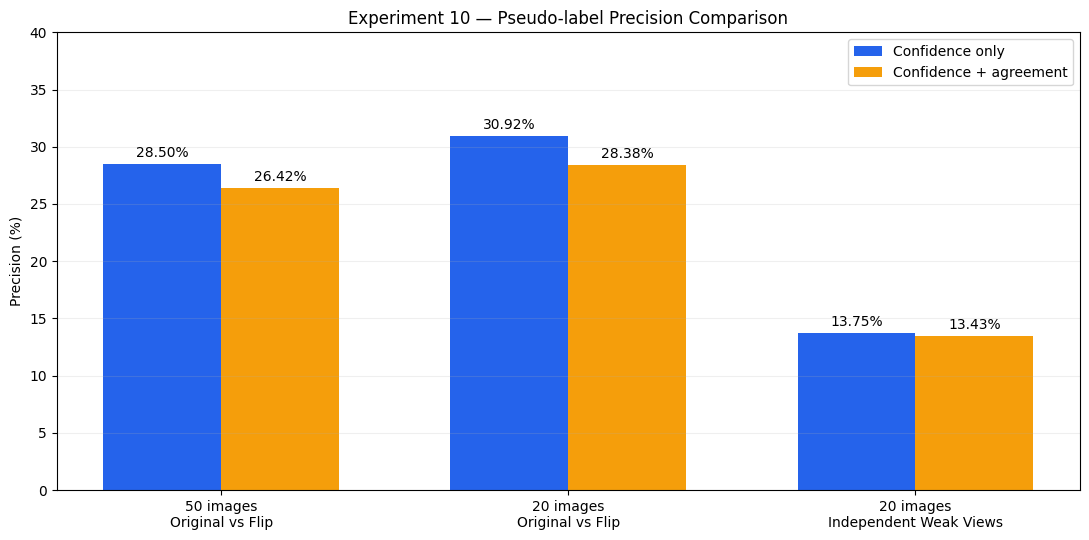

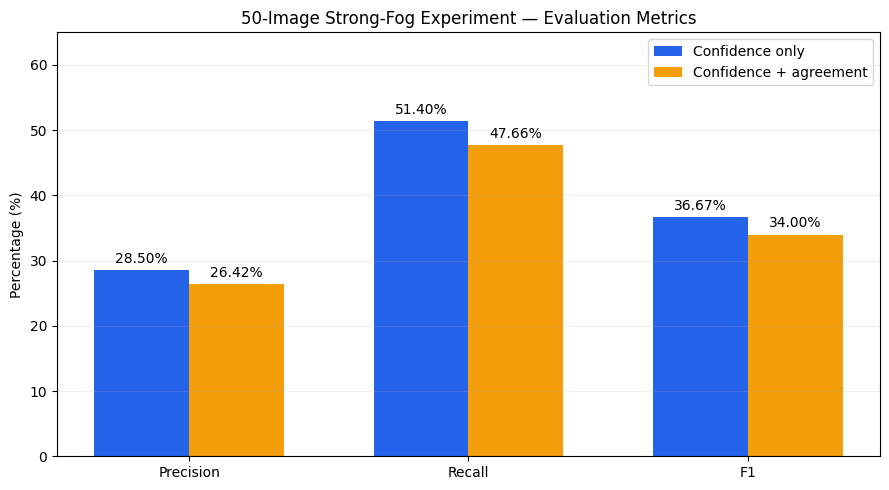

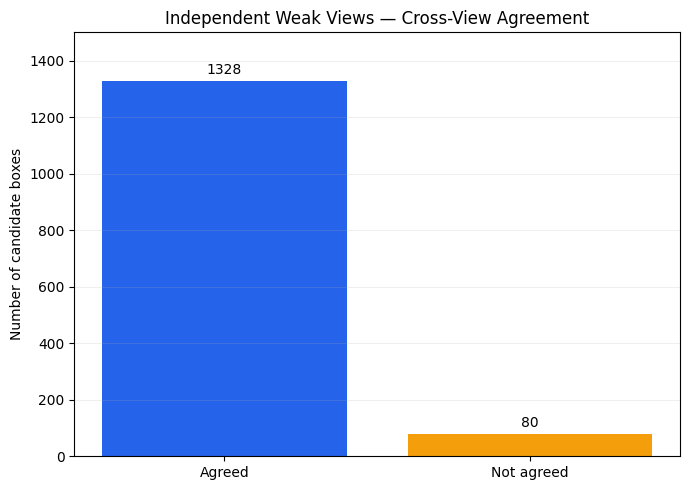

All three Experiment 10 charts generated successfully.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Experiment 10: previously evaluated results
experiments = [
    "50 images\nOriginal vs Flip",
    "20 images\nOriginal vs Flip",
    "20 images\nIndependent Weak Views",
]

confidence_precision = [28.50, 30.92, 13.75]
agreement_precision = [26.42, 28.38, 13.43]

# Chart 1: Precision comparison
x = np.arange(len(experiments))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 5.5))
bars1 = ax.bar(x - width/2, confidence_precision, width,
               label="Confidence only", color="#2563EB")
bars2 = ax.bar(x + width/2, agreement_precision, width,
               label="Confidence + agreement", color="#F59E0B")

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)
ax.set_xticks(x)
ax.set_xticklabels(experiments)
ax.set_ylabel("Precision (%)")
ax.set_title("Experiment 10 — Pseudo-label Precision Comparison")
ax.set_ylim(0, 40)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

# Chart 2: Precision, Recall, F1 — 50-image experiment
metrics = ["Precision", "Recall", "F1"]
confidence = [28.50, 51.40, 36.67]
agreement = [26.42, 47.66, 34.00]

x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width/2, confidence, width,
               label="Confidence only", color="#2563EB")
bars2 = ax.bar(x + width/2, agreement, width,
               label="Confidence + agreement", color="#F59E0B")

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Percentage (%)")
ax.set_title("50-Image Strong-Fog Experiment — Evaluation Metrics")
ax.set_ylim(0, 65)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

# Chart 3: Independent weak-view agreement
total_candidates = 1408
agreed_candidates = 1328
not_agreed = total_candidates - agreed_candidates

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ["Agreed", "Not agreed"],
    [agreed_candidates, not_agreed],
    color=["#2563EB", "#F59E0B"]
)

ax.bar_label(bars, padding=3)
ax.set_ylabel("Number of candidate boxes")
ax.set_title("Independent Weak Views — Cross-View Agreement")
ax.set_ylim(0, 1500)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

print("All three Experiment 10 charts generated successfully.")



## Comparison with Harmonious Teacher (CVPR 2023)

**Reference:** Deng et al., "Harmonious Teacher for Cross-domain Object Detection," CVPR 2023.

### 1. Related Work

Harmonious Teacher addresses the mismatch between classification confidence and localization quality in cross-domain object detection.

It introduces harmonious model learning to improve consistency between classification and localization predictions, and harmonious sample reweighting to incorporate both classification confidence and predicted localization quality into pseudo-label weighting during teacher–student adaptation.

### 2. Difference from the Present Experiment

Harmonious Teacher focuses on classification–localization score harmony and uses the resulting quality information during training.

Our experiment instead examines whether a frozen teacher's detections remain consistent in class and bounding-box location across two weakly augmented views of the same target image.

We compare:

- Confidence-only pseudo-label selection.
- Confidence plus cross-view class-and-location agreement.

Both methods retain an equal number of boxes within each experiment. Ground-truth annotations are used only after selection for evaluation.

No student retraining is performed in this experiment.

### 3. Experimental Results

| Experiment | Retained boxes per method | Confidence-only precision | Confidence + agreement precision |
|---|---:|---:|---:|
| 50 images: original vs. horizontal flip | 1,351 | 28.50% | 26.42% |
| 20 images: original vs. horizontal flip | 511 | 30.92% | 28.38% |
| 20 images: independent weak photometric views | 1,258 | 13.75% | 13.43% |

In all three comparisons, adding cross-view agreement reduced precision relative to confidence-only selection.

The independent weak-view experiment produced agreement for 1,328 of 1,408 candidate boxes (94.32%), indicating that this agreement criterion was not sufficiently discriminative in the tested setting.

The different augmentation experiments have different candidate pools and retained-box counts, so their absolute precision values should not be interpreted as a controlled comparison between augmentation types.

### 4. Interpretation and Limitations

The results do not support the hypothesis that the tested class-and-location agreement filter improves pseudo-label precision over confidence-only selection.

Harmonious Teacher provides relevant prior work demonstrating the importance of localization quality, but its classification–localization harmony mechanism is distinct from the cross-view agreement criterion evaluated here.

These experiments measure pseudo-label selection quality only. They do not establish improvements in object-detection mAP or downstream student training.

### 5. Proposed Next Step

Investigate whether agreement is more informative specifically among lower-confidence detections, particularly the 0.70–0.80 confidence interval.

A future extension may combine classification confidence, cross-view stability, and localization-quality estimates.

Any claimed training improvement will require matched student-training comparisons, repeated seeds, and evaluation on an additional adverse-weather dataset.
